# 03 · Class areas for reporting

**Question:** do the platform's land-cover areas give each class its true area, nationally and per region, prefecture, ecoregion and hexagon?

The shares are the means of Esri's 10 m pixels in each 100 m cell, so their sum over a unit is the unit's 10 m area. The platform counts one class per cell instead: its national class areas (`LandCoverClassArea`, from the published 100 m land-cover map by `landuse_tool/class_areas.py`) and any area read off its maps. The reporting units are those of the deforestation work (`deforestation_experiments/1_areas/02_reporting_areas`): ADM1 and ADM2 (geoBoundaries), ecoregions (RESOLVE 2017) and H3 hexagons at resolution 7, each cell going to the unit holding its centre. Computations are in `scripts/areas100.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import areas100 as A
C, R, G = A.C, A.R, A.G

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200)
YEAR = 2024

## 1 · National areas

Guinea's class areas from the shares and from one class per cell, against the national composition the platform publishes (`GET /api/landuse/composition/`, read on the live platform, nothing changed).

In [2]:
nat = A.national(YEAR) / 100                                          # km²
nat["one class per cell vs shares (%)"] = 100 * (nat["one class per cell"] / nat["shares (10 m)"] - 1)
comp, data_date = A.platform_composition()
nat["platform composition"] = comp[YEAR].reindex(nat.index) / 100
nat["platform vs shares (ratio)"] = nat["platform composition"] / nat["shares (10 m)"]
box, inside = A.grid_box_ha()
total = comp[YEAR].drop(["Snow / ice", "no data"]).sum()
print(f"Platform composition: years {list(comp.columns)}, data date {data_date}; its classes add up to {total / 1e6:.2f} M ha "
      f"against Guinea's {inside / 1e6:.2f} M ha ({total / inside:.2f} times) and the grid's bounding box {box / 1e6:.2f} M ha")
C.save("03_national_areas_2024.csv", nat)
nat.round(2)

Platform composition: years [2024, 2025], data date 2026-10-21; its classes add up to 43.36 M ha against Guinea's 24.65 M ha (1.76 times) and the grid's bounding box 51.74 M ha


,shares (10 m),one class per cell,one class per cell vs shares (%),platform composition,platform vs shares (ratio)
Water,1384.68,1387.76,0.22,12543.54,9.06
Trees,128946.40,129156.01,0.16,240036.94,1.86
Flooded vegetation,1798.86,1798.76,-0.01,3412.17,1.90
Crops,3329.73,3292.39,-1.12,4639.48,1.39
Built area,2806.82,2777.48,-1.05,5020.68,1.79
Bare ground,63.47,60.83,-4.16,86.08,1.36
Rangeland,108142.81,108000.05,-0.13,167872.66,1.55


**Reading:**

* **One class per cell gives the large classes within 0.2 %** of their 10 m area. Small, scattered classes are undercounted: crops by 1.1 %, built area by 1.0 %, bare ground by 4.2 % (the majority-rule bias, Moody & Woodcock 1994; notebook 01 shows it is three times larger at 250 m).
* **The platform's published composition is not Guinea's.** Its classes add up to 43.4 million ha, 1.76 times Guinea's 24.6 million ha and close to the 51.7 million ha of the grid's bounding box: the published map is summed over the box, neighbouring countries and part of the sea included (water is 9 times Guinea's). This agrees with the check made in the deforestation work. Only 2024 and 2025 are published.
* So the composition chart needs two fixes: count inside Guinea's outline, and take the area from the shares.

## 2 · Areas per reporting unit

For each class and level, how far one class per cell is from the shares: the share of the class's area placed in the wrong unit, the median and 95th percentile error over units holding at least 10 ha of the class, and the national bias. "+nearest" gives the border cells outside every polygon to the nearest unit.

In [3]:
err = C.save("03_unit_errors_2024.csv", A.all_unit_errors(YEAR))
view = err.pivot_table(index="Class", columns="Level", values="Misplaced (% of total)").reindex(
    columns=["ADM1+nearest", "ADM2+nearest", "ecoregion", "h3"]).reindex([C.NAMES[c] for c in C.CLASSES])
print("Share of each class's area in the wrong unit (%), one class per cell against the shares")
view.round(2)

Share of each class's area in the wrong unit (%), one class per cell against the shares


Level,ADM1+nearest,ADM2+nearest,ecoregion,h3
Class,,,,
Water,1.04,1.44,0.75,8.85
Trees,0.16,0.28,0.24,1.80
Flooded vegetation,0.11,0.21,0.17,2.86
Crops,1.12,1.13,1.13,5.37
Built area,1.07,1.09,1.04,6.49
Bare ground,4.16,4.83,4.57,13.00
Rangeland,0.16,0.32,0.25,2.17


In [4]:
err[err.Level.isin(["ADM2+nearest", "h3"])].set_index(["Level", "Class"]).drop(columns="Units").round(2)

Misplaced (% of total)  Median |error| (%)  95th pct |error| (%)  Bias (%)
Level        Class                                                                                         
h3           Water                                 8.85                8.17                 32.56      0.22
             Trees                                 1.80                1.65                 11.23      0.16
             Flooded vegetation                    2.86                2.85                 17.33     -0.01
             Crops                                 5.37                4.74                 24.88     -1.12
             Built area                            6.49                5.88                 25.20     -1.05
             Bare ground                          13.00                6.35                 28.70     -4.16
             Rangeland                             2.17                2.09                 14.92     -0.13
ADM2+nearest Water                                 1.44                1.60                 17.53      0.22
             Trees                                 0.28                0.23                  0.78      0.16
             Flooded vegetation                    0.21                5.70                 50.39     -0.01
             Crops                                 1.13                1.76                  9.02     -1.12
             Built area                            1.09                1.27                  2.94     -1.05
             Bare ground                           4.83               15.07                 33.03     -4.16
             Rangeland                             0.32                0.24                  1.92     -0.13

**Reading:**

* **Regions, prefectures and ecoregions are close for the large classes** (trees and rangeland within 0.3 %). Crops and built area are 1.1 % low in every unit, the national bias. Bare ground is 4–5 % off.
* **Hexagons carry more error:** 2–9 % of each class in the wrong hexagon at resolution 7, and 13 % of bare ground. A hexagon holds about 500 cells, so cells split between classes do not average out.
* **Flooded vegetation varies most between prefectures** (95th percentile 50 %): it lies in narrow strips along rivers and the coast, where cells are mixed.

## 3 · Border cells

The geoBoundaries ADM1 and ADM2 polygons do not cover the whole ADM0 outline the grid uses: cells along the border fall outside every polygon. The regional tables then add up to less than Guinea.

In [5]:
border = pd.DataFrame({k: A.unit_totals(k, YEAR) for k in ["ADM1", "ADM2", "ADM1+nearest", "ADM2+nearest"]})
border.index.name = "Sum of the units vs Guinea (%)"
C.save("03_border_totals_2024.csv", border)
border.round(3)

,ADM1,ADM2,ADM1+nearest,ADM2+nearest
Sum of the units vs Guinea (%),,,,
Water,-8.765,-8.765,-0.0,0.0
Trees,-0.421,-0.421,-0.0,-0.0
Flooded vegetation,-3.734,-3.734,-0.0,-0.0
Crops,-0.917,-0.917,-0.0,-0.0
Built area,-0.464,-0.464,0.0,0.0
Bare ground,-3.113,-3.113,0.0,0.0
Rangeland,-0.608,-0.608,0.0,-0.0


**Reading:** the regional and prefecture tables miss 8.8 % of Guinea's water and 3.7 % of its flooded vegetation, both concentrated along the coast, and 0.4–0.9 % of the other classes. Giving the border cells to the nearest unit makes the tables add up to the national figure exactly, as in the deforestation work.

## 4 · On the map

The error of one class per cell, per prefecture, for the two classes it undercounts most among those people report: crops and built area.

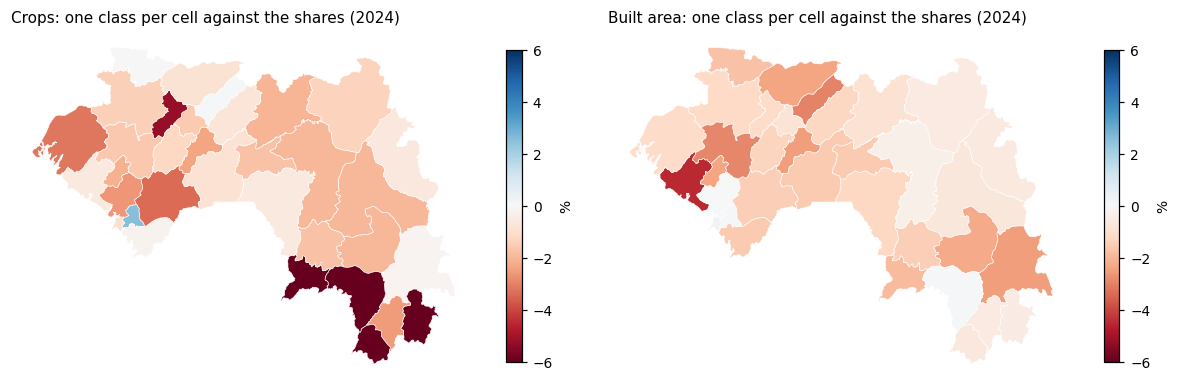

In [6]:
t = A.by_unit("ADM2+nearest", YEAR)
gdf = R.units("ADM2").set_index("unit")
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, cls in zip(axes, ["Crops", "Built area"]):
    pct = 100 * (t["class"][cls] / t["shares"][cls] - 1)
    gdf.assign(err=pct.reindex(gdf.index)).plot(column="err", cmap="RdBu", vmin=-6, vmax=6, ax=ax, edgecolor="#ffffff",
                                                  linewidth=0.4, legend=True, legend_kwds={"shrink": 0.6, "label": "%"})
    ax.set_title(f"{cls}: one class per cell against the shares ({YEAR})", loc="left", fontsize=10)
    ax.set_axis_off()
plt.tight_layout(); plt.show()

**Reading:** one class per cell undercounts crops in 32 of the 34 prefectures and built area in 30. The largest gaps are where a class is rare and scattered: crops in the forest prefectures of the south-east (Yomou −20 %, Guéckédou −9 %, Macenta −9 %, Lola −7 %, where they cover only 1–6 km² each), and built area in rural prefectures (Boffa −4.5 %, Koubia, Télimélé −3 %); Conakry's built area is exact. The bias is systematic, not noise.

## 5 · What this means

* **Report class areas from the shares**, nationally and per unit: they are the 10 m areas. One class per cell undercounts crops and built area by 1 % and bare ground by 4 %, and misplaces 2–13 % of each class among hexagons.
* **Fix the composition chart:** sum inside Guinea's outline, not the bounding box (now 1.76 times Guinea), from the shares.
* **Give border cells to the nearest unit**, so the regional tables add up to Guinea (now up to 8.8 % of the water missing).
* These are suggestions for the platform's reporting; the forecast itself is scored on the class map (notebooks 04–07).
* **Next, notebook 04:** the deployed method as `main` runs it.

**Sources**

* Moody, A., Woodcock, C.E. (1994). Scale-dependent errors in the estimation of land-cover proportions: implications for global land-cover datasets. *Photogrammetric Engineering and Remote Sensing* 60(5), 585–594.
* GEDH platform repository, `main`: `landuse_tool/class_areas.py`, `backend/landuse_api/composition.py`.